# Postcards from My Jungle — image generation

Trains a small unconditional diffusion model (DDPM) **from scratch** on photos of real animals, then samples 50 images of creatures that don't exist.
Based on the course notebook / the 🤗 diffusers *train a diffusion model* tutorial.

**Runtime → Change runtime type → T4 GPU** before running.

Workflow: set the knobs in **Config** → train → look at the sample grids → adjust and re-run → generate the final 50 → download `images.zip` into the repo's `images/` folder. Record each run in the **Experiment log** at the bottom; you'll need it for the README.

In [1]:
!pip install -q diffusers accelerate datasets

In [2]:
import os, math, random, zipfile
from dataclasses import dataclass

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from datasets import load_dataset
from torchvision import transforms
from diffusers import UNet2DModel, DDPMScheduler, DDPMPipeline
from diffusers.optimization import get_cosine_schedule_with_warmup

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "(no GPU — training will be very slow)")

Device: cuda Tesla T4


## Config — the experiment knobs

The three things the assignment asks you to vary are **`subset_size`** (dataset size), **`image_size`** (resolution) and **`num_epochs`**.

Rough T4 timings to plan with: 64 px × 3,000 images ≈ 1–1.5 min/epoch; 128 px is about 4× slower. Free Colab sessions can disconnect, so turn on the Drive cell below for long runs.

Other datasets that work by changing `dataset_name` / `image_column` / `keep_labels`:
- `huggan/AFHQv2` — cats, dogs, wild animals (`image`, labels cat/dog/wild)
- `huggan/smithsonian_butterflies_subset` — 1,000 butterflies (`image`, set `keep_labels=()`)
- `cifar10` — 32 px, includes birds, frogs, deer… (`img`, column `label`)

In [3]:
@dataclass
class Config:
    dataset_name: str = "huggan/AFHQv2"
    image_column: str = "image"
    keep_labels: tuple = ("wild",)   # () keeps every class
    subset_size: int = 3000          # experiment: 1000 / 3000 / all
    image_size: int = 64             # experiment: 32 / 64 / 128
    num_epochs: int = 40             # experiment: 20 / 40 / 80
    batch_size: int = 32
    learning_rate: float = 1e-4
    lr_warmup_steps: int = 500
    sample_every_epochs: int = 10
    num_train_timesteps: int = 1000
    num_images_to_generate: int = 50
    seed: int = 498
    output_dir: str = "run"
    images_dir: str = "images"

config = Config()
random.seed(config.seed); np.random.seed(config.seed); torch.manual_seed(config.seed)
os.makedirs(config.output_dir, exist_ok=True)
os.makedirs(config.images_dir, exist_ok=True)
config

Config(dataset_name='huggan/AFHQv2', image_column='image', keep_labels=('wild',), subset_size=3000, image_size=64, num_epochs=40, batch_size=32, learning_rate=0.0001, lr_warmup_steps=500, sample_every_epochs=10, num_train_timesteps=1000, num_images_to_generate=50, seed=498, output_dir='run', images_dir='images')

In [4]:
# Optional: save checkpoints and sample grids to Google Drive so a disconnect doesn't lose the run
SAVE_TO_DRIVE = False
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    config.output_dir = "/content/drive/MyDrive/postcards-from-my-jungle/run"
    os.makedirs(config.output_dir, exist_ok=True)

## Dataset

dataset_infos.json:   0%|          | 0.00/827 [00:00<?, ?B/s]

data/train-00000-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  497MB            

data/train-00000-of-00013.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  501MB            

data/train-00001-of-00013.parquet: downloading bytes:           |  0.00B            

...

data/train-00012-of-00013.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/15803 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'label'],
    num_rows: 15803
})
Classes: ['cat', 'dog', 'wild']


Filter:   0%|          | 0/15803 [00:00<?, ? examples/s]

Training on 3000 images


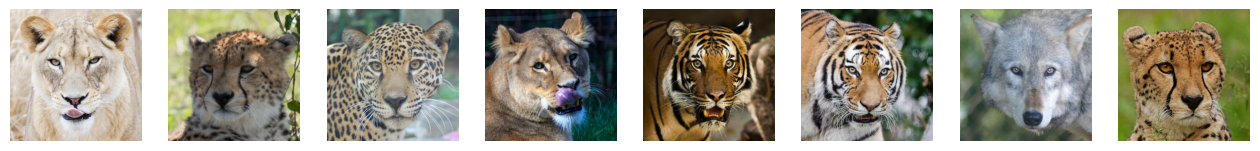

In [5]:
dataset = load_dataset(config.dataset_name, split="train")
print(dataset)

label_feature = dataset.features.get("label")
if config.keep_labels and label_feature is not None and hasattr(label_feature, "names"):
    print("Classes:", label_feature.names)
    keep_ids = {label_feature.names.index(l) for l in config.keep_labels if l in label_feature.names}
    dataset = dataset.filter(lambda l: l in keep_ids, input_columns="label")

dataset = dataset.shuffle(seed=config.seed).select(range(min(config.subset_size, len(dataset))))
print("Training on", len(dataset), "images")

fig, axs = plt.subplots(1, 8, figsize=(16, 2.2))
for ax, ex in zip(axs, dataset.select(range(8))):
    ax.imshow(ex[config.image_column]); ax.axis("off")
plt.show()

In [6]:
preprocess = transforms.Compose([
    transforms.Resize(config.image_size, interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.CenterCrop(config.image_size),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),   # scale to [-1, 1]
])

def transform(batch):
    return {"images": [preprocess(img.convert("RGB")) for img in batch[config.image_column]]}

dataset.set_transform(transform)
train_dataloader = torch.utils.data.DataLoader(
    dataset, batch_size=config.batch_size, shuffle=True, num_workers=2, drop_last=True)
print(len(train_dataloader), "batches per epoch")

93 batches per epoch


## Model

A small UNet (~25M parameters) that works at 32, 64 or 128 px. Bigger `block_out_channels` = more capacity but slower.

In [7]:
model = UNet2DModel(
    sample_size=config.image_size,
    in_channels=3,
    out_channels=3,
    layers_per_block=2,
    block_out_channels=(64, 128, 256, 256),
    down_block_types=("DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "DownBlock2D"),
    up_block_types=("UpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D"),
).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

noise_scheduler = DDPMScheduler(num_train_timesteps=config.num_train_timesteps)
optimizer = torch.optim.AdamW(model.parameters(), lr=config.learning_rate)
lr_scheduler = get_cosine_schedule_with_warmup(
    optimizer, num_warmup_steps=config.lr_warmup_steps,
    num_training_steps=len(train_dataloader) * config.num_epochs)
scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))


@torch.no_grad()
def sample(n, seed, steps=1000):
    model.eval()
    pipe = DDPMPipeline(unet=model, scheduler=noise_scheduler)
    pipe.set_progress_bar_config(disable=True)
    generator = torch.Generator(device=device).manual_seed(seed)
    images = pipe(batch_size=n, generator=generator, num_inference_steps=steps).images
    model.train()
    return images


def make_grid(images, cols=8):
    w, h = images[0].size
    rows = math.ceil(len(images) / cols)
    grid = Image.new("RGB", (cols * w, rows * h))
    for i, im in enumerate(images):
        grid.paste(im, ((i % cols) * w, (i // cols) * h))
    return grid

25.3M parameters


## Train

Every `sample_every_epochs` the notebook saves a grid of 16 samples (same seed each time, so you can watch the same creatures form) and a checkpoint.

epoch 1/40:   0%|          | 0/93 [00:00<?, ?it/s]

epoch   1  loss 0.7623


epoch 2/40:   0%|          | 0/93 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x790e217d0b80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x790e217d0b80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch   2  loss 0.1983


...

epoch 9/40:   0%|          | 0/93 [00:00<?, ?it/s]

epoch   9  loss 0.0459


epoch 10/40:   0%|          | 0/93 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x790e217d0b80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x790e217d0b80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch  10  loss 0.0418


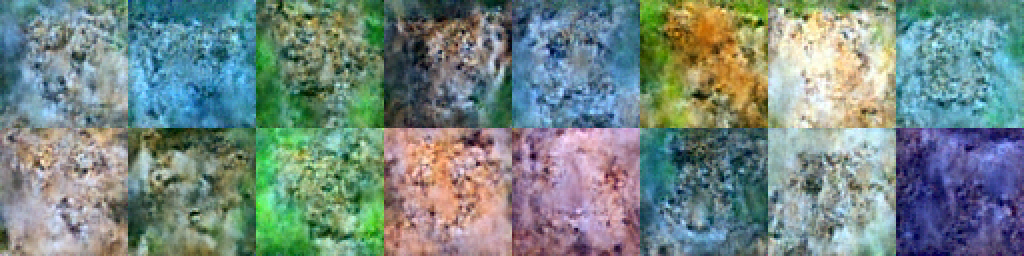

epoch 11/40:   0%|          | 0/93 [00:00<?, ?it/s]

epoch  11  loss 0.0399


epoch 12/40:   0%|          | 0/93 [00:00<?, ?it/s]

epoch  12  loss 0.0390


epoch 13/40:   0%|          | 0/93 [00:00<?, ?it/s]

...

epoch 19/40:   0%|          | 0/93 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x790e217d0b80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
AssertionError: can only test a child process
Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x790e217d0b80><function _MultiProcessingDataLoaderIter.__del__ at 0x790e217d0b80>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dat

epoch  19  loss 0.0371


epoch 20/40:   0%|          | 0/93 [00:00<?, ?it/s]

epoch  20  loss 0.0357


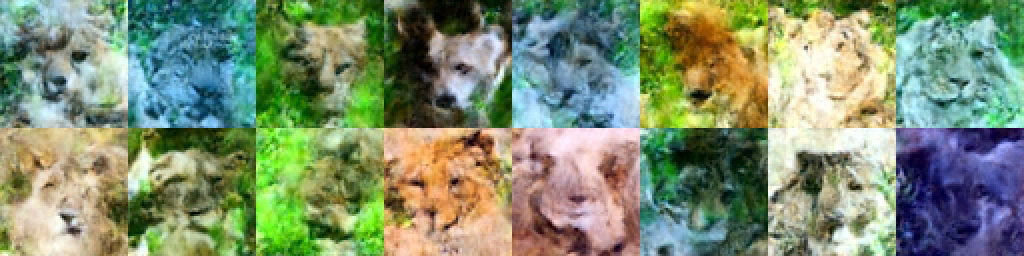

epoch 21/40:   0%|          | 0/93 [00:00<?, ?it/s]

epoch  21  loss 0.0330


epoch 22/40:   0%|          | 0/93 [00:00<?, ?it/s]

epoch  22  loss 0.0367


epoch 23/40:   0%|          | 0/93 [00:00<?, ?it/s]

...

epoch 29/40:   0%|          | 0/93 [00:00<?, ?it/s]

epoch  29  loss 0.0358


epoch 30/40:   0%|          | 0/93 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x790e217d0b80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x790e217d0b80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
AssertionError: Exception ignored in: can only test a child process<function _MultiProcessingDataLoaderIter.__del_

epoch  30  loss 0.0345


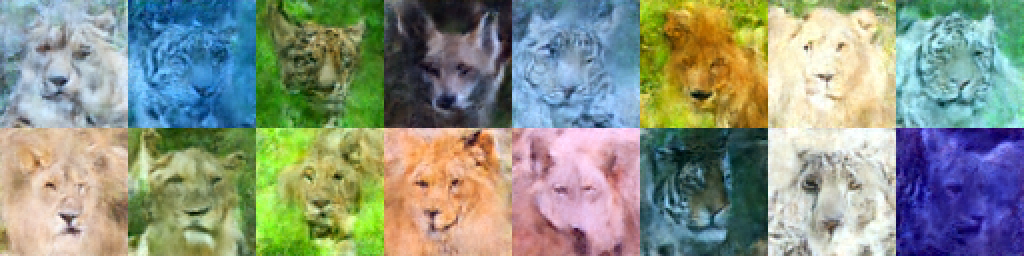

epoch 31/40:   0%|          | 0/93 [00:00<?, ?it/s]

epoch  31  loss 0.0319


epoch 32/40:   0%|          | 0/93 [00:00<?, ?it/s]

epoch  32  loss 0.0316


epoch 33/40:   0%|          | 0/93 [00:00<?, ?it/s]

...

epoch 39/40:   0%|          | 0/93 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x790e217d0b80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x790e217d0b80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x790e217d0b80>  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

AssertionErrorTraceback 

epoch  39  loss 0.0319


epoch 40/40:   0%|          | 0/93 [00:00<?, ?it/s]

epoch  40  loss 0.0319


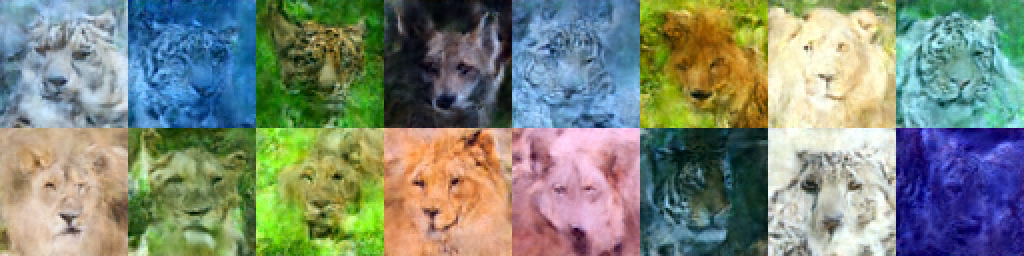

In [8]:
losses = []
for epoch in range(config.num_epochs):
    model.train()
    running = 0.0
    bar = tqdm(train_dataloader, desc=f"epoch {epoch + 1}/{config.num_epochs}", leave=False)
    for batch in bar:
        clean = batch["images"].to(device)
        noise = torch.randn_like(clean)
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps,
                                  (clean.shape[0],), device=device).long()
        noisy = noise_scheduler.add_noise(clean, noise, timesteps)

        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            noise_pred = model(noisy, timesteps, return_dict=False)[0]
        loss = F.mse_loss(noise_pred.float(), noise)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        lr_scheduler.step()

        running += loss.item()
        bar.set_postfix(loss=f"{loss.item():.4f}")

    losses.append(running / len(train_dataloader))
    print(f"epoch {epoch + 1:3d}  loss {losses[-1]:.4f}")

    if (epoch + 1) % config.sample_every_epochs == 0 or epoch + 1 == config.num_epochs:
        grid = make_grid(sample(16, seed=config.seed), cols=8)
        grid.save(f"{config.output_dir}/samples_epoch_{epoch + 1:03d}.png")
        display(grid.resize((grid.width * 2, grid.height * 2), Image.NEAREST))
        model.save_pretrained(f"{config.output_dir}/unet")

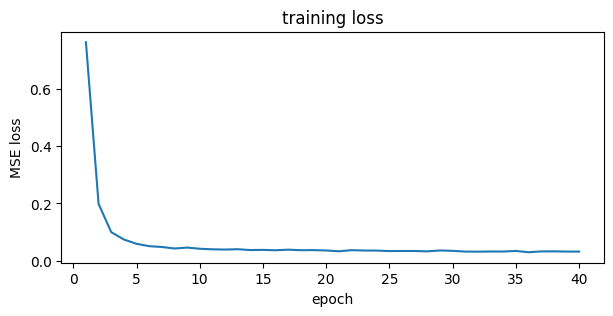

In [9]:
plt.figure(figsize=(7, 3))
plt.plot(range(1, len(losses) + 1), losses)
plt.xlabel("epoch"); plt.ylabel("MSE loss"); plt.title("training loss")
plt.savefig(f"{config.output_dir}/loss.png", dpi=120, bbox_inches="tight")
plt.show()

In [10]:
# Optional: reload a saved checkpoint instead of training again
# model = UNet2DModel.from_pretrained(f"{config.output_dir}/unet").to(device)

## Generate the 50 imagined animals

Saved as `images/animal_01.png` … `animal_50.png` — the filenames the website expects. They're saved at the native training resolution; the site displays them with crisp pixel scaling, which suits the lo-fi look.

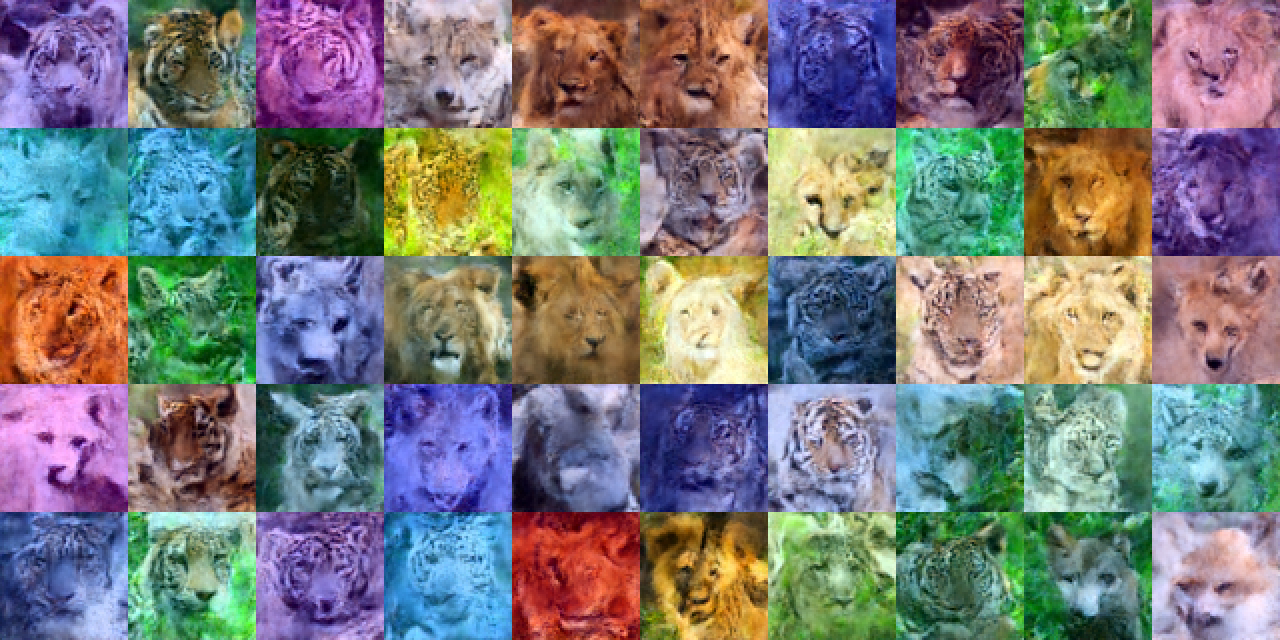

In [11]:
all_images = []
batch = 10
for b in range(math.ceil(config.num_images_to_generate / batch)):
    n = min(batch, config.num_images_to_generate - len(all_images))
    all_images += sample(n, seed=config.seed + 1000 + b)

for i, im in enumerate(all_images, start=1):
    im.save(f"{config.images_dir}/animal_{i:02d}.png")

grid = make_grid(all_images, cols=10)
grid.save(f"{config.output_dir}/final_50.png")
display(grid.resize((grid.width * 2, grid.height * 2), Image.NEAREST))

In [12]:
from google.colab import files

with zipfile.ZipFile("images.zip", "w") as z:
    for name in sorted(os.listdir(config.images_dir)):
        z.write(os.path.join(config.images_dir, name))
files.download("images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
from google.colab import files
files.download('images.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Experiment log

Fill this in as you go — the README needs it.

| run | dataset / classes | images | resolution | epochs | train time | final loss | what the samples looked like |
|---|---|---|---|---|---|---|---|
| 1 | AFHQv2 wild | 1,000 | 64 | 30 | | | |
| 2 | AFHQv2 wild | 3,000 | 64 | 60 | | | |
| 3 | AFHQv2 wild | 3,000 | 128 | 40 | | | |

**Chosen run:** … because …